# DRAMP: paired measurements at different dilution

A supplementary source analysis, not an acceptance protocol. Compare explicit half-life measurements under a common source record ID. The hypothesis is λ_obs=f λ_neat, hence f·t_half,obs should be comparable between dilutions. Peptide concentration and unknown error type may also affect the result; no labels are rescaled or exported to clean.

In [1]:
DATA_SOURCE = "dramp"
NOTEBOOK_ID = "0_02c_dramp_dilution_pairs"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol, CLEAN_COLUMNS
from proteolysis_data_manager.analysis.half_life.overview import cavaco_comparison, dilution_pairs, overlaps, linked_labels, FEATURES
from proteolysis_data_manager.protocols.half_life.conditions import counts, PARAMETERS, plot_conditions
from proteolysis_data_manager.integration.half_life.normalization import known, load_source_records
from proteolysis_data_manager.protocols.half_life.conditions import condition_frame
from proteolysis_data_manager.integration.half_life.labels import CLASS_BINS, CLASS_SCHEME
from proteolysis_data_manager.analysis.half_life.visualization import formatted_table, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS, duration_summary, plot_duration_distributions
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
all_sources = condition_frame(load_source_records(DATA_ROOT))
data = all_sources.loc[all_sources.source.eq(DATA_SOURCE)].copy()
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / NOTEBOOK_ID
RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.12})
def table(frame, name):
    if len(frame)>20: display(HTML(f"<p>Preview: 20 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame)))

def figure(fig, name):
    fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def before_after(before, after, name):
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    for ax,field,label in [(axes[0],"length","Peptide length (residues)"),(axes[1],"half_life_seconds","log10 half-life (minutes; exact point labels)")]:
        a=pd.to_numeric(before[field],errors="coerce").dropna(); b=pd.to_numeric(after[field],errors="coerce").dropna()
        if field=="half_life_seconds":
            a=a[a>0]; b=b[b>0]; bins=time_bins(a,bins=18)
            label="Half-life (physical time; logarithmic spacing)"
        else: bins=np.histogram_bin_edges(a,bins=18) if len(a) else np.linspace(0,1,19)
        ax.hist(a,bins=bins,histtype="step",lw=2,color="#4477AA",label=f"Before (n={len(a)})")
        ax.hist(b,bins=bins,histtype="step",lw=2,color="#EE7733",label=f"After (n={len(b)})")
        if field=="half_life_seconds": readable_time_axis(ax)
        ax.set(xlabel=label,ylabel="Observations"); ax.legend()
    fig.tight_layout(); figure(fig,name)


Source overviews reconstruct the detailed inventory from verified `raw/` files in memory, to inspect original wording and documentation. The public `normalized/observations.parquet` has the compact 23-column contract. See `normalized/remarks_<source>.md` for exceptional label decisions and shared-record enrichment.

## Split measurements and their original descriptions

In [2]:
split=data[data.source_record_id.duplicated(keep=False)]
table(split[["source_record_id","observation_id","measurement_clause_raw","species","matrix","matrix_fraction","half_life_seconds","reported_error_seconds","uncertainty_kind"]],"split_measurements.tsv")
pairs=dilution_pairs(data); table(pairs,"dilution_pairs.tsv")

source_record_id,observation_id,measurement_clause_raw,species,matrix,matrix_fraction,half_life_seconds,reported_error_seconds,uncertainty_kind
DRAMP29881,dramp:stability:DRAMP29881:measurement_1,The half-live is 68 ±15 min in 25% aqueous mouse serum,mouse,serum,0.25,4080,900,unspecified_plus_minus
DRAMP29881,dramp:stability:DRAMP29881:measurement_2,25±4 min in full mouse serum.,mouse,serum,1,1500,240,unspecified_plus_minus


source_record_id,low_fraction_observation,high_fraction_observation,low_fraction,high_fraction,low_fraction_half_life_seconds,high_fraction_half_life_seconds,observed_half_life_ratio,linear_dilution_expected_ratio,low_fraction_neat_proxy_seconds,high_fraction_neat_proxy_seconds,interpretation
DRAMP29881,dramp:stability:DRAMP29881:measurement_1,dramp:stability:DRAMP29881:measurement_2,0.25,1,4080,1500,2.72,4,1020,1500,Exploratory constant-hazard hypothesis; error kind unknown; no peptide-concentration adjustment.


## Observed and expected ratios

This is an exploratory consistency check. An observed ratio differing from the expected fraction ratio does not justify rejecting a source. The original measurements and reported errors are preserved.

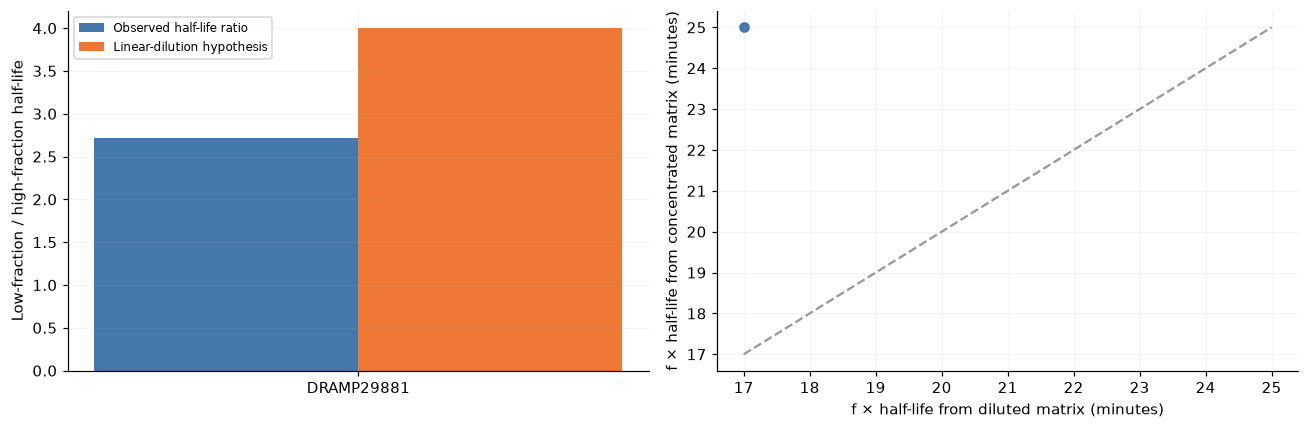

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
if len(pairs):
 x=np.arange(len(pairs)); width=.35
 axes[0].bar(x-width/2,pairs.observed_half_life_ratio,width,label="Observed half-life ratio",color="#4477AA")
 axes[0].bar(x+width/2,pairs.linear_dilution_expected_ratio,width,label="Linear-dilution hypothesis",color="#EE7733")
 axes[0].set_xticks(x,pairs.source_record_id); axes[0].set(ylabel="Low-fraction / high-fraction half-life"); axes[0].legend(fontsize=8)
 axes[1].scatter(pairs.low_fraction_neat_proxy_seconds/60,pairs.high_fraction_neat_proxy_seconds/60,color="#4477AA")
 lo=min(pairs.low_fraction_neat_proxy_seconds.min(),pairs.high_fraction_neat_proxy_seconds.min())/60; hi=max(pairs.low_fraction_neat_proxy_seconds.max(),pairs.high_fraction_neat_proxy_seconds.max())/60
 axes[1].plot([lo,hi],[lo,hi],ls="--",color="#999999"); axes[1].set(xlabel="f × half-life from diluted matrix (minutes)",ylabel="f × half-life from concentrated matrix (minutes)")
else:
 for ax in axes: ax.text(.5,.5,"No explicit matched dilution pairs",transform=ax.transAxes,ha="center")
fig.tight_layout(); figure(fig,"dilution_hypothesis.png")